In [1]:
import os, sys
import scanpy as sc

from pathlib import Path
_p = Path(".").resolve()
while not (_p / "src" / "config.py").exists() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p))
from src.config import ANALYSIS_DIR, FIGURES_DIR


In [2]:
os.getcwd()

'/Users/stanleydale/user_generated/breault-lab/single-cell/notebooks/D2_Lapa'

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))
from src.markers import cell_type_markers

In [4]:
## include a scanpy save directory for the figures

In [5]:
os.getcwd()

'/Users/stanleydale/user_generated/breault-lab/single-cell/analysis'

In [7]:
d2_lapa = sc.read_h5ad(ANALYSIS_DIR / "data-objects/clustered/clustered_egfDuod_D2_Lapa_DZ.h5ad")

In [8]:
d2_lapa

AnnData object with n_obs × n_vars = 60337 × 28941
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [9]:
d2_lapa.n_vars
d2_lapa.var_names[:5]
'LGR5' in d2_lapa.var_names, 'AXIN2' in d2_lapa.var_names, 'ASCL2' in d2_lapa.var_names


(True, True, True)

In [10]:
print(d2_lapa.obs['orig.ident'].unique())

['D2_Lapa']
Categories (1, object): ['D2_Lapa']


In [11]:
print(d2_lapa.obs['leiden'].unique())

['4', '1', '0', '2', '13', ..., '34', '23', '36', '31', '27']
Length: 39
Categories (39, object): ['0', '1', '2', '3', ..., '35', '36', '37', '38']


In [12]:
ISC_markers = cell_type_markers['ISCs']    
PC_markers = cell_type_markers['PCs'] 
Proliferating_PC_markers = cell_type_markers['Proliferating PCs']
Enterocyte_markers = cell_type_markers['Enterocytes']
Goblet_markers = cell_type_markers['Goblet cells']
EEC_markers = cell_type_markers['EECs']


## The cell block below is for the built-in scoring of genes, that we initially tried

In [13]:
#sc.tl.score_genes(d2_lapa, gene_list = ISC_markers, score_name='ISC_score')

In [14]:
#d2_lapa.var.head(20)

In [15]:
'NEUROD1' in d2_lapa.var.index

True

In [16]:
d2_lapa

AnnData object with n_obs × n_vars = 60337 × 28941
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [17]:
#sc.tl.score_genes(d2_lapa, gene_list = PC_markers, score_name='PC_score')

In [18]:
'NEUROG3' in d2_lapa.var.index

True

In [19]:
#sc.tl.score_genes(d2_lapa, gene_list = Proliferating_PC_markers, score_name='Proliferating PC score')

In [20]:
#sc.tl.score_genes(d2_lapa, gene_list = Enterocyte_markers, score_name='Enterocyte score')

In [21]:
d2_lapa

AnnData object with n_obs × n_vars = 60337 × 28941
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [22]:
#sc.tl.score_genes(d2_lapa, gene_list = Goblet_markers, score_name='Goblet score')

In [23]:
#sc.tl.score_genes(d2_lapa, gene_list = EEC_markers, score_name='EEC score')

In [24]:
d2_lapa

AnnData object with n_obs × n_vars = 60337 × 28941
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [25]:
import pandas as pd
import numpy as np

#score_cols = ["ISC_score", "PC_score", 'Proliferating PC score', "Enterocyte score", "Goblet score", "EEC score"]
#lab_per_cell = d2_lapa.obs[score_cols].idxmax(axis=1)
#d2_lapa.obs["celltype_by_score"] = lab_per_cell.astype("category")


In [26]:
#clus = d2_lapa.obs["leiden"].astype("category")
#counts = pd.crosstab(clus, d2_lapa.obs["celltype_by_score"]).sort_index()
#props  = counts.div(counts.sum(1), axis=0).fillna(0.0)


In [27]:
#import matplotlib.pyplot as plt

#ax = props.plot(kind="bar", stacked=True, figsize=(9,3))
#ax.set_ylabel("proportion"); ax.set_xlabel("leiden")
#ax.legend(title="cell type", bbox_to_anchor=(1.02,1), loc="upper left")
#plt.tight_layout(); plt.show()


## Now we move to plotting heatmap panels for each set of marker genes across the entire umap

In [28]:
### Importantly, these are relative in terms of the colour, to the highest expression in that panel. This is driven by the vmax argument that we pass to sc.pl.umap

#### ISC markers

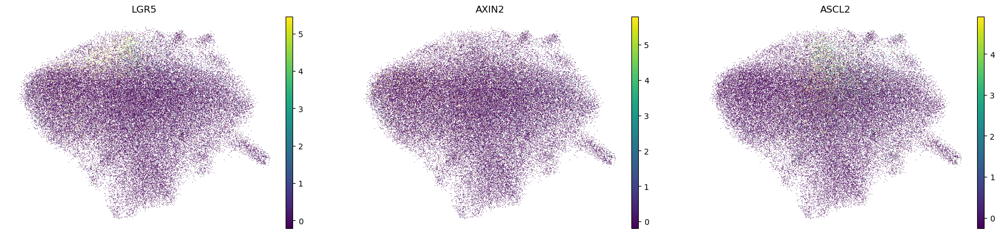

In [29]:
## I think these proportions are slightly confusing. It might be because we don't have all of the markers represented in the scoring

present = [g for g in ISC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

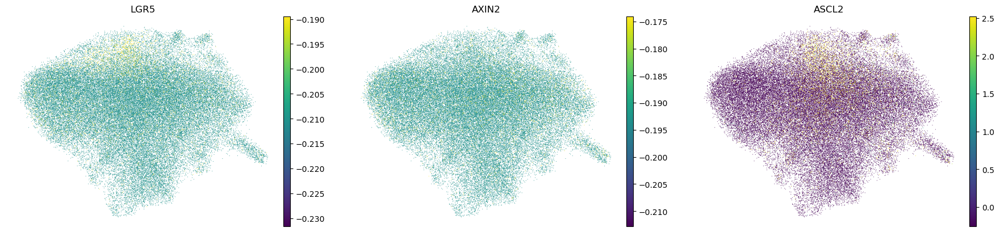

In [30]:
## Let's try and increase the dynamic range by squashing the scale

present = [g for g in ISC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

### Progenitor cell marker

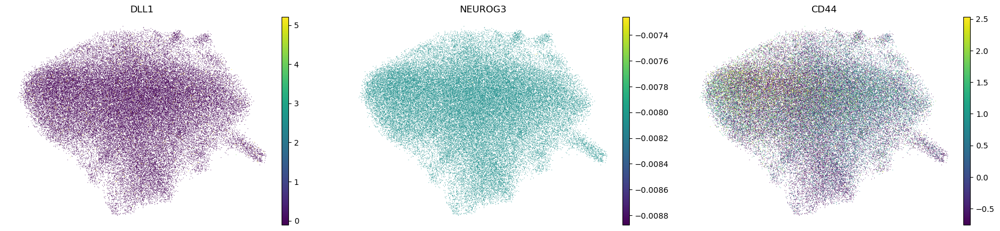

In [31]:
present = [g for g in PC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

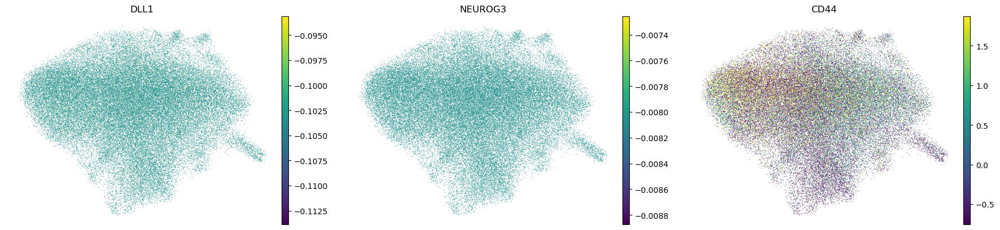

In [32]:
## Again I want to increase the dynamic range: 

present = [g for g in PC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

In [33]:
d2_lapa

AnnData object with n_obs × n_vars = 60337 × 28941
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

### Proliferating Progenitor Cells

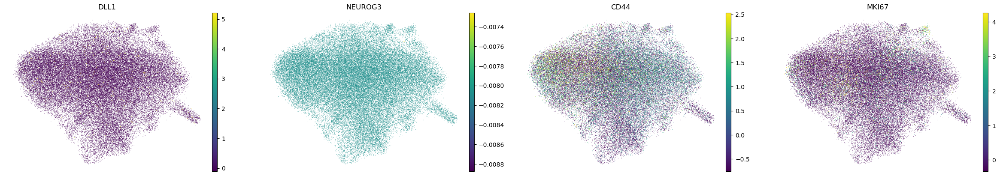

In [34]:
present = [g for g in Proliferating_PC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

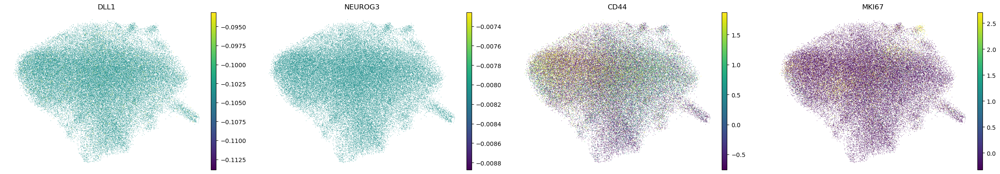

In [35]:
present = [g for g in Proliferating_PC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

### Enterocyte markers

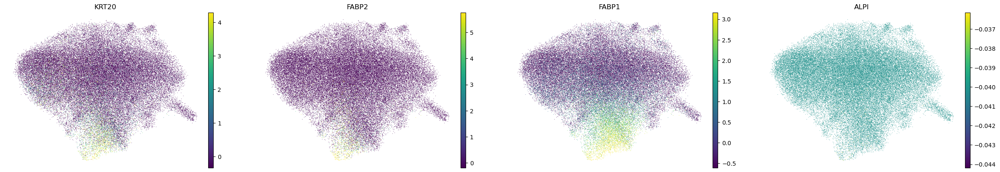

In [36]:
present = [g for g in Enterocyte_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

### Goblet cell markers

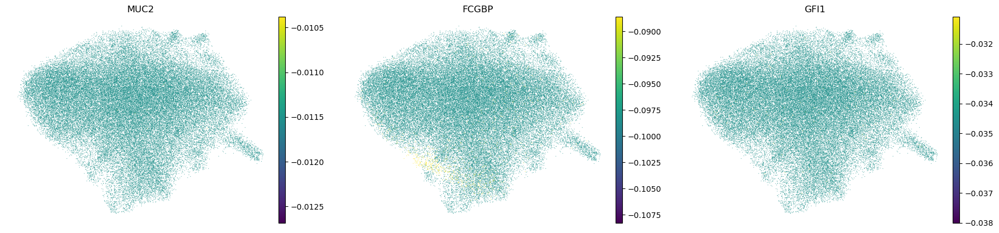

In [37]:
present = [g for g in Goblet_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

### Enteroendocrine Cell markers

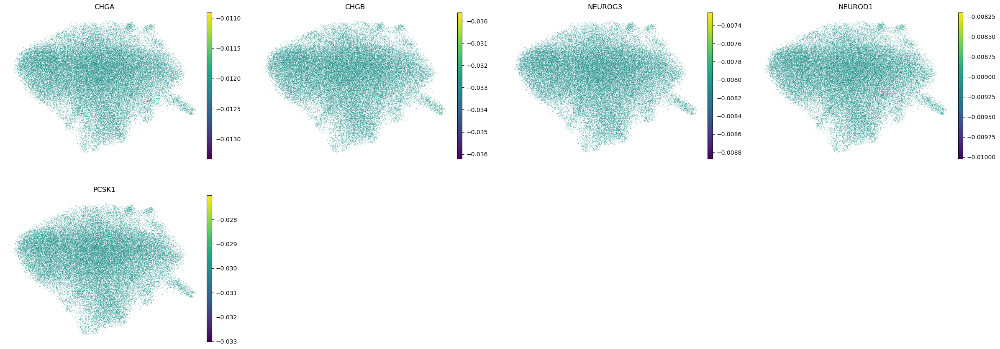

In [38]:
present = [g for g in EEC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

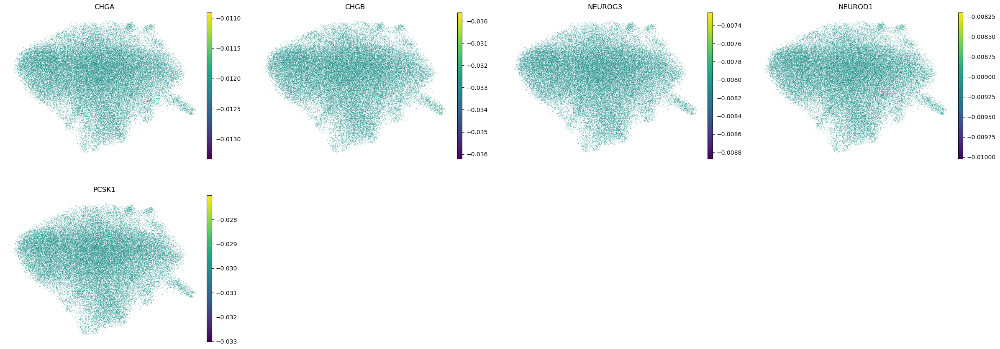

In [39]:
present = [g for g in EEC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p90",            # nicer dynamic range
    frameon=False
)

## Let's plot the entire set of markers, so that the scale is absolute for each marker


In [40]:
import scanpy as sc
import numpy as np
import pandas as pd

adata = d2_lapa  # <-- or your AnnData
cluster_key = "leiden"         # change if you used a different key

# Example markers dict:
# markers = {"Stem/ISC": ["LGR5", "ASCL2"], "Enterocyte": ["ALPI","APOA1"], ...}
# (Use your own dict here)
markers = cell_type_markers

# — ensure leiden is categorical & optional dendrogram ordering —
adata.obs[cluster_key] = adata.obs[cluster_key].astype("category")
sc.tl.dendrogram(adata, groupby=cluster_key)  # enables consistent ordering across plots

# — keep only genes present in adata.var_names (case-sensitive) —
varset = set(adata.var_names)
filtered_markers = {k: [g for g in v if g in varset] for k, v in markers.items()}
missing = {k: sorted(set(v) - varset) for k, v in markers.items() if any(g not in varset for g in v)}

# (optional) quick notice in notebook:
print("Missing genes (ignored):")
for k, lst in missing.items():
    if lst: print(f"  {k}: {', '.join(lst)}")

# If you prefer uppercase matching, uncomment this mapping:
# name_map = {g.upper(): g for g in adata.var_names}
# filtered_markers = {k: [name_map[g] for g in v if g.upper() in name_map] for k,v in markers.items()}

Missing genes (ignored):
  EECs: PAX4


[<Axes: title={'center': 'LGR5'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'AXIN2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ASCL2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'DLL1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'NEUROG3'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'CD44'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'MKI67'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'INSM1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'NEUROD1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'SOX4'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ATOH1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'KRT20'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FABP2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FABP1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ALPI'}, xlabel='UMAP1'

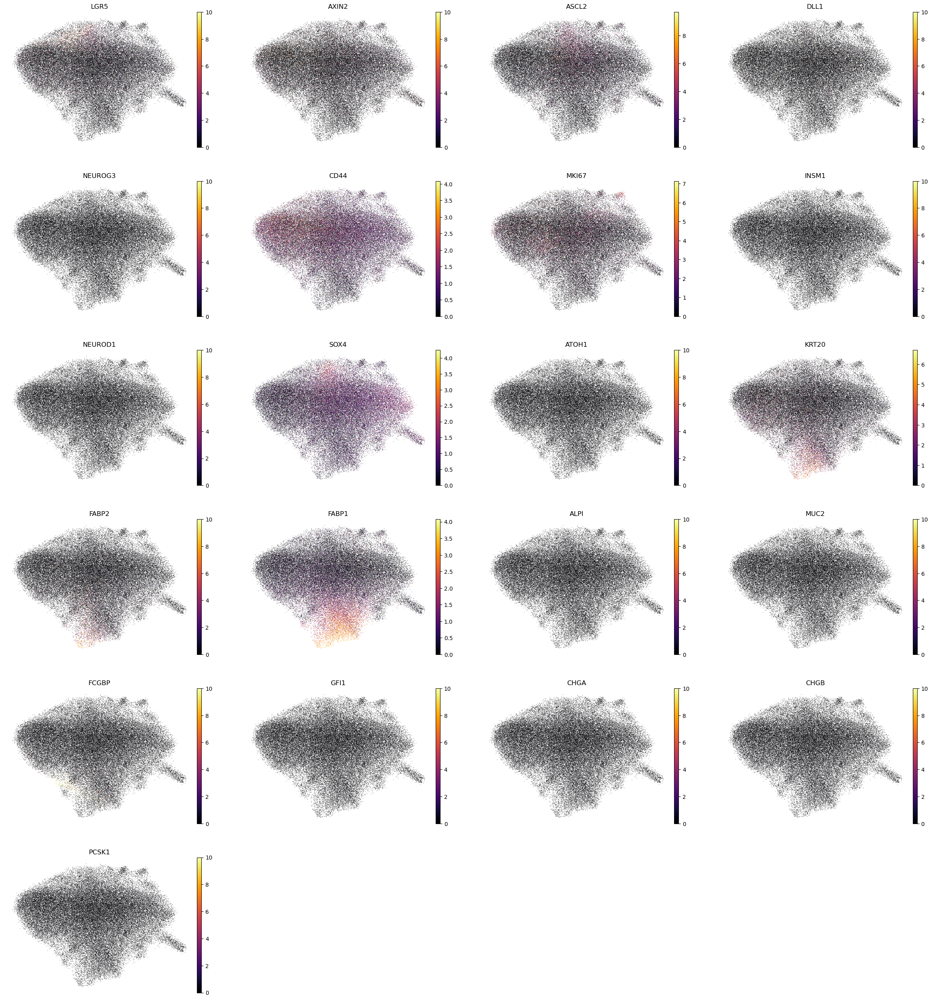

In [41]:

# Flatten your markers dict into a unique list
all_markers = []
for genes in filtered_markers.values():
    all_markers.extend(genes)
all_markers = list(dict.fromkeys(all_markers))  # preserve order, remove dups

sc.settings.figdir = str(FIGURES_DIR / "marker-genes/d2-lapa")

sc.pl.umap(
    adata,
    color=all_markers,         # list of genes
    vmin=0, vmax=None,         # adjust if needed
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False
)
sc.pl.umap(
    adata,
    color=all_markers,
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False,
    save="_d2_lapa_umap_marker_genes.pdf"
)


### Let's also go back and try a new set of ISC markers

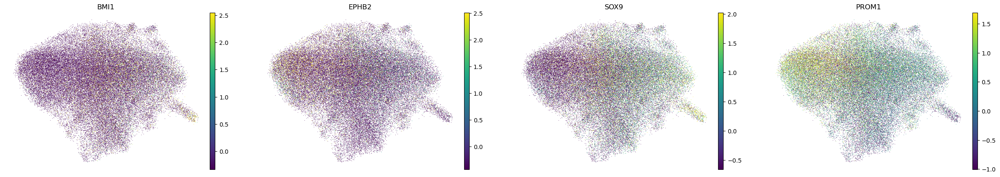

In [42]:
More_Isc_markers = ["BMI1", "EPHB2", "SOX9", "PROM1"]

## I think these proportions are slightly confusing. It might be because we don't have all of the markers represented in the scoring

present = [g for g in More_Isc_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

## Inflammatory secretory markers

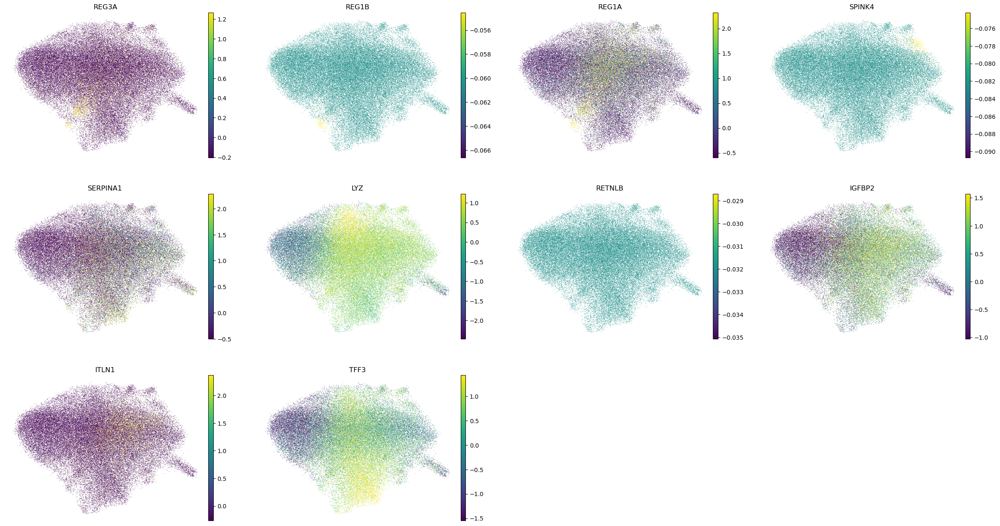

In [43]:
### Let's try plotting our inflammatory secretory markers

Inflammed_Secretory_PC_markers = ["REG3A",
"DEFA6",
"REG1B",
"REG1A",
"SPINK4",
"SERPINA1",
"LYZ",
"RETNLB",
"IGFBP2",
"ITLN1",
"TFF3"]


present = [g for g in Inflammed_Secretory_PC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]

sc.pl.umap(
    d2_lapa,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

#### Bubble plot

categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.
categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

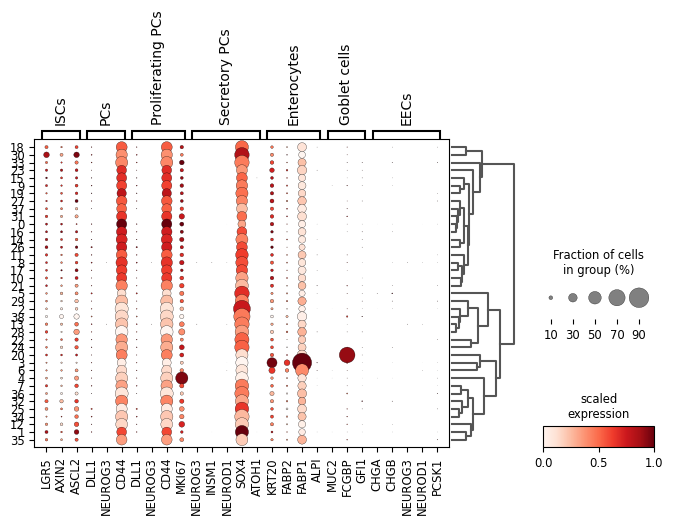

In [44]:
sc.pl.dotplot(
    adata,
    filtered_markers,              # dict[group] = list of genes
    groupby=cluster_key,
    dendrogram=True,               # uses the sc.tl.dendrogram result
    standard_scale="var",          # scale per gene for comparability
    mean_only_expressed=True,      # makes size reflect % expressing, color = mean
    swap_axes=False,               # clusters on x-axis (set True to flip)
    show=False,
    colorbar_title="scaled\nexpression",
    figsize=(8, 4)
)
# Save exactly like Scanpy expects (relative to sc.settings.figdir if set)
sc.pl.dotplot(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    standard_scale="var",
    mean_only_expressed=True,
    show=False,
    save="_markers_by_leiden_dotplot.pdf"   # yields e.g. 'figures/dotplot_markers_by_leiden_dotplot.pdf'
)



### Bubble plot our inflammed markers

{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

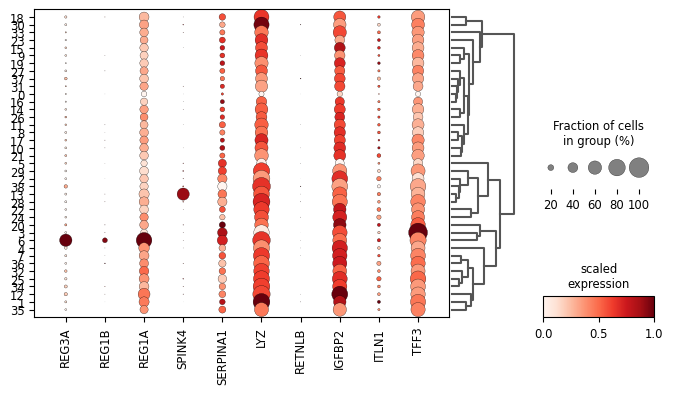

In [48]:
present = [g for g in Inflammed_Secretory_PC_markers
           if (hasattr(d2_lapa, "raw") and d2_lapa.raw is not None and g in d2_lapa.raw.var_names) or
              (g in d2_lapa.var_names)]


sc.pl.dotplot(
    adata,
    present,              # dict[group] = list of genes
    groupby=cluster_key,
    dendrogram=True,               # uses the sc.tl.dendrogram result
    standard_scale="var",          # scale per gene for comparability
    mean_only_expressed=True,      # makes size reflect % expressing, color = mean
    swap_axes=False,               # clusters on x-axis (set True to flip)
    show=False,
    colorbar_title="scaled\nexpression",
    figsize=(8, 4)
)
# Save exactly like Scanpy expects (relative to sc.settings.figdir if set)
sc.pl.dotplot(
    adata,
    present,
    groupby=cluster_key,
    dendrogram=True,
    standard_scale="var",
    mean_only_expressed=True,
    show=False,
    save="_markers_by_leiden_dotplot.pdf"   # yields e.g. 'figures/dotplot_markers_by_leiden_dotplot.pdf'
)



In [ ]:
sc.pl.umap(
    adata,
    color=all_markers,         # list of genes
    vmin=0, vmax=None,         # adjust if needed
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False
)